# FMCW Radar: How It Works

**Frequency-Modulated Continuous Wave (FMCW) radar** measures the range (and, from the Doppler shift, the velocity) of a target by continuously transmitting a signal whose frequency changes linearly with time — a **chirp** — rather than transmitting short pulses. It is the operating principle behind most automotive radars, radar altimeters, FM-CW level sensors, and many cloud/precipitation radars.

Instead of timing how long a short pulse takes to return (as in pulsed radar), an FMCW radar converts the round-trip travel time into a **frequency difference** between the transmitted and received chirps, which can be measured very precisely with an FFT.

This notebook builds an FMCW radar simulation from scratch, in five steps:

1. Generate the transmitted chirp.
2. Simulate the received echo — a delayed, weaker copy of the chirp reflected from a target at a known range.
3. **Mix** (multiply) the transmitted and received signals to obtain a low-frequency "beat" signal.
4. Take the FFT of the beat signal to find the beat frequency.
5. Convert the beat frequency back into target range.

The next cell imports the libraries used throughout; after that we sketch the radar's block diagram and the shape of the transmitted/received chirps in frequency vs. time, before moving to the numerical simulation.

In [49]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import scipy.signal

## System block diagram

A basic FMCW radar consists of the following functional blocks:

- **Chirp generator (VCO):** produces a continuous sinusoid whose instantaneous frequency ramps linearly from $f_0$ to $f_1$ over the sweep duration $T$ — the `f0`, `f1`, and `chirp_length` variables used below.
- **Splitter:** taps off a copy of the transmitted chirp to serve as the **local oscillator (LO)** reference for the mixer.
- **TX antenna:** radiates the chirp toward the target.
- **Target:** reflects a delayed, attenuated copy of the chirp back to the radar. The round-trip delay is $\tau = 2R/c$, where $R$ is the target range and $c$ the speed of light (`time_delay` below).
- **RX antenna (+ LNA):** receives and amplifies the weak echo.
- **Mixer:** multiplies the received echo by the LO reference, producing sum- and difference-frequency components (this is the `mixed` array computed below).
- **Low-pass filter:** removes the high sum-frequency component, leaving only the low-frequency **beat signal** at the difference frequency $\Delta f$.
- **ADC + FFT / range processing:** digitizes the beat signal and computes its spectrum. The beat frequency shows up as a spectral peak, which is converted to range.

The figure below draws this signal chain; solid arrows are electrical connections, dashed arrows represent the signal propagating through free space to and from the target.

![FMCW radar block diagram](tex/fmcw_block_diagram.png)

## Transmitted vs. received chirp: frequency vs. time

Because the chirp's frequency ramps linearly with time at a constant rate (the **chirp slope** $S = B/T = (f_1-f_0)/T$), a time delay $\tau$ turns directly into a frequency difference. At any instant $t$ during the overlap of the two chirps:

$$f_{RX}(t) = f_{TX}(t-\tau)$$

Since $f_{TX}$ is a linear ramp, $f_{TX}(t) - f_{TX}(t-\tau) = S\,\tau$ — a **constant** frequency offset, the beat frequency:

$$\Delta f = S\,\tau = \frac{f_1-f_0}{T}\cdot\frac{2R}{c}$$

This is the key trick that makes FMCW radar work: measuring a *frequency* (via an FFT) is far easier and more precise than measuring a tiny *time delay* directly, especially with a limited sampling rate.

The plot below sketches the transmitted and received sawtooth chirps on a shared frequency-vs-time axis. **The delay is exaggerated** so it is visible — in the actual simulation below, `target_range = 2 m` gives a round-trip delay of only about 13 ns compared to a 2 ms sweep, so the two ramps would appear to overlap almost exactly if plotted to scale.

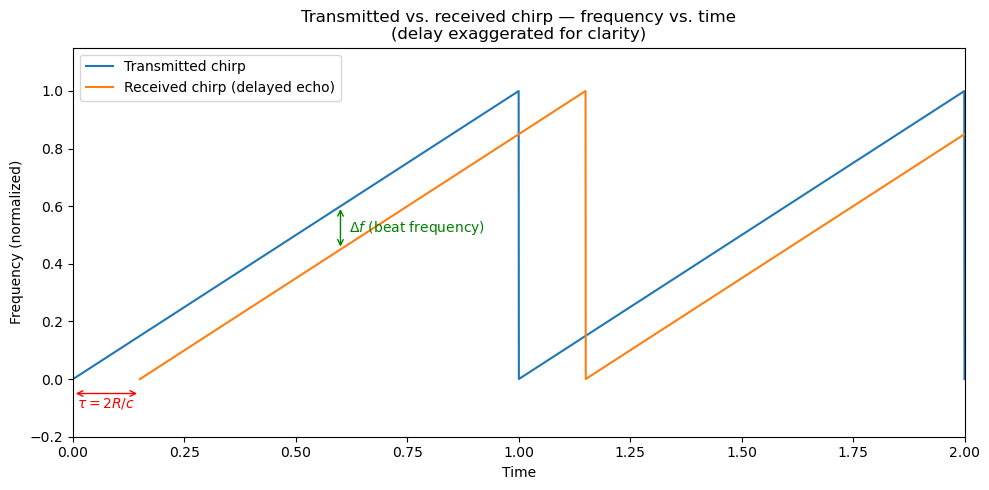

In [ ]:
# Illustrative sweep (arbitrary/normalized units, NOT the same scale as the
# simulation below) -- the round-trip delay is exaggerated so that both
# chirps and the resulting beat frequency are visible in the same plot.
T_sweep = 1.0                 # one sweep period
f_start, f_stop = 0.0, 1.0    # normalized start/stop frequency
n_periods = 2
tau = 0.15 * T_sweep          # exaggerated round-trip delay

t = np.linspace(0, n_periods * T_sweep, 4000)

def sawtooth_freq(t, delay=0.0):
    tt = (t - delay) % T_sweep
    f = f_start + (f_stop - f_start) * tt / T_sweep
    return np.where(t < delay, np.nan, f)

f_tx = sawtooth_freq(t)
f_rx = sawtooth_freq(t, delay=tau)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t, f_tx, color='tab:blue', label='Transmitted chirp')
ax.plot(t, f_rx, color='tab:orange', label='Received chirp (delayed echo)')

# Mark the beat frequency at one instant
t_mark = 0.6
f_tx_mark = sawtooth_freq(np.array([t_mark]))[0]
f_rx_mark = sawtooth_freq(np.array([t_mark]), delay=tau)[0]
ax.annotate('', xy=(t_mark, f_tx_mark), xytext=(t_mark, f_rx_mark),
            arrowprops=dict(arrowstyle='<->', color='green'))
ax.text(t_mark + 0.02, (f_tx_mark + f_rx_mark) / 2, r'$\Delta f$ (beat frequency)',
        color='green', va='center')

# Mark the round-trip delay
ax.annotate('', xy=(tau, -0.05), xytext=(0, -0.05),
            arrowprops=dict(arrowstyle='<->', color='red'))
ax.text(tau / 2, -0.1, r'$\tau = 2R/c$', color='red', ha='center')

ax.set_xlabel('Time')
ax.set_ylabel('Frequency (normalized)')
ax.set_title('Transmitted vs. received chirp — frequency vs. time\n(delay exaggerated for clarity)')
ax.legend(loc='upper left')
ax.set_ylim(-0.2, 1.15)
ax.set_xlim(0, n_periods * T_sweep)
plt.tight_layout()
plt.show()

## Simulating the chirp in code

The cell below sets the radar parameters used throughout this notebook — the sweep bandwidth (`f0` to `f1`), the sweep duration (`chirp_length`), and the range of a single point target (`target_range`) — and generates the transmitted chirp waveform using `scipy.signal.chirp`. The plot shows the transmitted chirp's amplitude vs. time, zoomed in on the first few thousand samples so that individual oscillations are visible (the full sweep is 2 ms long).

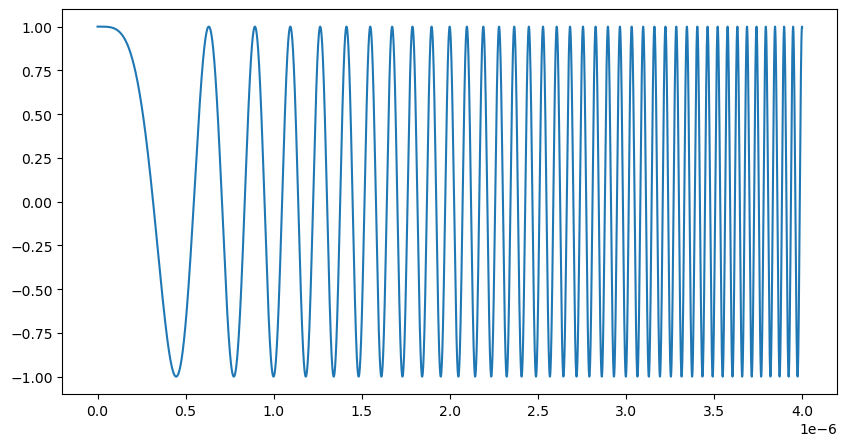

In [52]:
chirp_length=2e-3      # Seconds
f0=30e9                # Hz
f1=40e9                # Hz
c = 3e8                # meters per second
target_range = 2       # meters
n_samples = 5000000    # dimensionless
time_delay = 2*target_range/c
sampling_rate = n_samples/chirp_length
t_axis = np.linspace(0, chirp_length, n_samples)
transmit_chirp = scipy.signal.chirp(t_axis, f0=f0, f1=f1, t1=chirp_length, method='linear')

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
n_samples_plot = 10000
ax.plot(t_axis[:n_samples_plot], transmit_chirp[:n_samples_plot])

## Simulating the received echo and mixing

To simulate the receiver, the transmitted chirp is time-shifted by `time_delay` ($\tau = 2R/c$) to create `receive_chirp` — this stands in for the echo reflected from the target. (A real echo would also be attenuated and noisy, but for this exercise we only care about its frequency content.)

The two signals are then **mixed** — multiplied sample-by-sample — to produce `mixed`. Multiplying two sinusoids of frequencies $f_{TX}(t)$ and $f_{RX}(t)$ produces components at the *sum* $f_{TX}(t)+f_{RX}(t)$ (fast) and the *difference* $f_{TX}(t)-f_{RX}(t) = \Delta f$ (slow, and constant during the overlap of the two chirps). The plot below shows the mixed signal in the time domain: the fast oscillation is the sum-frequency term, while the much slower envelope corresponds to $\Delta f$ — the beat frequency we'll extract next.

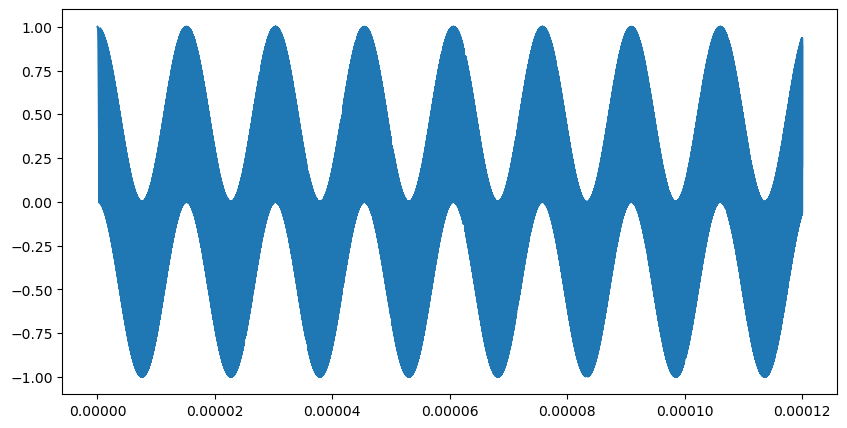

In [53]:
samples_until_return = int(sampling_rate * time_delay)
t_axis = np.linspace(0, chirp_length, n_samples+samples_until_return)
nan_pad = np.full(samples_until_return, np.nan)
receive_chirp = np.append(nan_pad, transmit_chirp, axis=0)
transmit_chirp = np.append(transmit_chirp, nan_pad, axis=0)
mixed = np.multiply(receive_chirp, transmit_chirp)

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
n_samples_plot = 300000
ax.plot(t_axis[:n_samples_plot], mixed[:n_samples_plot])

## Extracting the beat frequency with an FFT

A real receiver would low-pass filter `mixed` to remove the sum-frequency term before digitizing it; here we instead go straight to the FFT of the overlapping region of `mixed` (the portion where both the transmitted and received chirps are present). Because the beat frequency $\Delta f$ is constant over that whole interval, it appears as a single, sharp, dominant peak in the power spectrum — visible below on a log scale.

/tmp/ipykernel_47414/3587441153.py:10: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(0, 5e8)


Text(0, 0.5, 'Power Density')

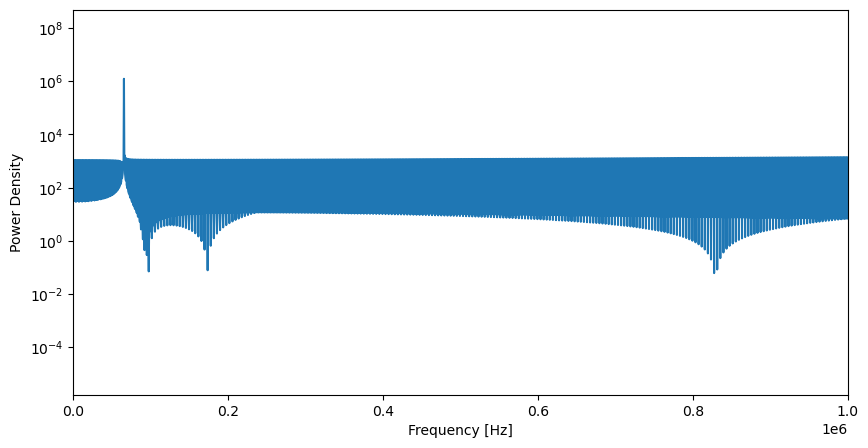

In [54]:
fft = scipy.fft.fft(mixed[samples_until_return:-samples_until_return])
fft_power = abs(fft[0:n_samples//2])
xf = scipy.fft.fftfreq(n_samples,chirp_length/n_samples)
x_ax_p = xf[0:n_samples//2]

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(x_ax_p, fft_power)
ax.set_xlim(0, 1e6)
ax.set_yscale('log')
ax.set_ylim(0, 5e8)
ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel('Power Density')

## From beat frequency to range

The location of the spectral peak, `f_max_power`, is the beat frequency $\Delta f$. Recall from the frequency-vs-time discussion above that

$$\Delta f = \frac{B}{T}\,\tau = \frac{f_1-f_0}{T}\cdot\frac{2R}{c}$$

where $B = f_1 - f_0$ is the sweep bandwidth and $T = $ `chirp_length`. Solving for the range $R$:

$$R = \frac{c\,\Delta f\,T}{2B}$$

which is exactly the formula evaluated below. The result should come out close to the `target_range = 2 m` used to generate the simulated echo.

In [55]:
df = pd.DataFrame({'freq':x_ax_p, 'power':fft_power})
f_max_power = df['freq'][df['power']==np.max(df['power'])].values[0]
radar_range = c*f_max_power*chirp_length/(2*(f1-f0))
print(f'Radar range: {radar_range} m')

Radar range: 1.98 m


## Summary

This simulation captured the essence of FMCW ranging:

- A linear frequency sweep (chirp) is transmitted continuously.
- The echo from a target is simply a **delayed copy** of that same chirp.
- Because frequency is a linear function of time within a chirp, a time delay $\tau$ becomes a constant **frequency offset** $\Delta f$ between the transmitted and received signals.
- Mixing the two signals and filtering out the sum-frequency term isolates $\Delta f$ as a **beat signal** whose frequency is easy to measure precisely with an FFT — much more precisely than timing $\tau$ directly, which is why FMCW is so widely used for short- and medium-range radar.
- The measured $\Delta f$ converts directly to range via $R = c\,\Delta f\,T / (2B)$.

A real system would add: a low-noise amplifier and matched receiver filtering, coherent processing across multiple chirps to also extract **Doppler velocity**, and handling of multiple simultaneous targets (each produces its own beat frequency, showing up as a separate FFT peak).